# Ataques Adversariais: Comprometendo Sistemas Baseados em Machine Learning

## Importações

In [1]:
!pip install gdown

import gdown

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from PIL import Image
import matplotlib.pyplot as plt
import os
import random
import zipfile
import shutil
import numpy as np

## Carregamento de Dados

In [3]:
!gdown --folder https://drive.google.com/drive/folders/1ZJIITWgAplI4_Aohj_Hw5Nuz9KEw_ZhM

Retrieving folder contents
Processing file 1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp cats_dogs_small.zip
Processing file 1eSkfzfI50ayZJvMPZp2XPCSXqt4Qu1JC glasses_no_glasses.zip
Processing file 1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQFBh mask_no_mask.zip
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp
From (redirected): https://drive.google.com/uc?id=1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp&confirm=t&uuid=d90626f4-d84c-43bf-837b-46fcfad38606
To: /content/Data/cats_dogs_small.zip
100% 32.3M/32.3M [00:00<00:00, 53.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1eSkfzfI50ayZJvMPZp2XPCSXqt4Qu1JC
To: /content/Data/glasses_no_glasses.zip
100% 3.96M/3.96M [00:00<00:00, 200MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQFBh
From (redirected): https://drive.google.com/uc?id=1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQFB

In [5]:
data_path = "/content/Data"

zip_files = [f for f in os.listdir(data_path) if f.endswith(".zip")]

print("Datasets disponíveis:\n")
for i, file in enumerate(zip_files, 1):
    print(f"{i} - {file}")

choice = input("\nDigite o número do dataset: ")

try:
    choice = int(choice)
    selected_zip = zip_files[choice - 1]
except:
    raise ValueError("Opção inválida!")

zip_path = os.path.join(data_path, selected_zip)

extract_path = os.path.join(data_path, selected_zip.replace(".zip", ""))
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

extract_name = os.path.basename(os.path.normpath(extract_path))
subdirs = [d for d in os.listdir(extract_path) if os.path.isdir(os.path.join(extract_path, d))]
nested_path = os.path.join(extract_path, extract_name)
class_subdirs = [d for d in subdirs if d != extract_name]

if os.path.isdir(nested_path) and class_subdirs:
    shutil.rmtree(nested_path)
    subdirs = class_subdirs
elif os.path.isdir(nested_path):
    subdirs = [extract_name]

if len(subdirs) == 1:
    inner_path = os.path.join(extract_path, subdirs[0])

    for item in os.listdir(inner_path):
        shutil.move(os.path.join(inner_path, item), extract_path)

    os.rmdir(inner_path)

print(f"\nDataset escolhido: {selected_zip}")
print(f"Extraído em: {extract_path}")

Datasets disponíveis:

1 - glasses_no_glasses.zip
2 - cats_dogs_small.zip
3 - mask_no_mask.zip

Dataset escolhido: cats_dogs_small.zip
Extraído em: /content/Data/cats_dogs_small


In [6]:
data_dir = extract_path

In [7]:
train_ds, val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="both",
    seed=42,
    image_size=(160, 160),
    batch_size=32
)

Found 1000 files belonging to 2 classes.
Using 800 files for training.
Using 200 files for validation.


In [8]:
print(train_ds.class_names)

['cats', 'dogs']


## Modelo de Classificação

In [9]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [10]:
model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [11]:
model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3


25/25 ━━━━━━━━━━━━━━━━━━━━ 30s 992ms/step - accuracy: 0.8400 - loss: 0.3869 - val_accuracy: 0.9400 - val_loss: 0.1880
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 39s 907ms/step - accuracy: 0.9500 - loss: 0.1618 - val_accuracy: 0.9600 - val_loss: 0.1255
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 40s 879ms/step - accuracy: 0.9613 - loss: 0.1199 - val_accuracy: 0.9650 - val_loss: 0.1069


In [12]:
model.evaluate(val_ds)

7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 514ms/step - accuracy: 0.9650 - loss: 0.1069


[0.10687121748924255, 0.9649999737739563]

## Mostrando as imagens

In [13]:
class_names = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]

paths = []

class_names = sorted(class_names)

for class_name in class_names:
    class_dir = os.path.join(data_dir, class_name)

    images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not images:
        continue

    chosen = random.choice(images)
    full_path = os.path.join(class_dir, chosen)

    paths.append(full_path)

if len(paths) >= 2:
    path_class1 = paths[0]
    path_class2 = paths[1]

print("Classe 1:", path_class1)
print("Classe 2:", path_class2)

Classe 1: /content/Data/cats_dogs_small/cats/2688.jpg
Classe 2: /content/Data/cats_dogs_small/dogs/12058.jpg


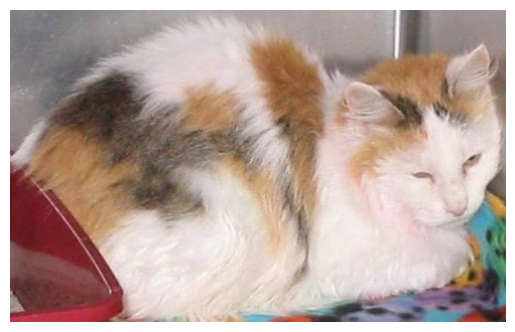

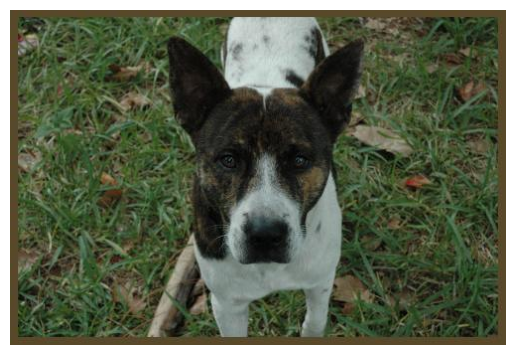

In [14]:
img_cat = Image.open(path_class1)
plt.imshow(img_cat)
plt.axis('off')
plt.show()

img_dog = Image.open(path_class2)
plt.imshow(img_dog)
plt.axis('off')
plt.show()

## Realizando a inferência

In [15]:
def predict_image(path, model, class_names):
    img = tf.keras.utils.load_img(path, target_size=(160,160))
    img = tf.keras.utils.img_to_array(img)

    img = tf.expand_dims(img, axis=0)

    pred = model.predict(img, verbose=0)[0][0]

    pred_class = int(pred >= 0.5)
    class_name = class_names[pred_class]

    confidence = pred if pred_class == 1 else 1 - pred

    return img, pred, class_name, confidence

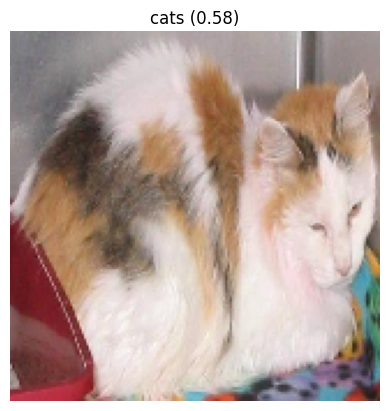

In [16]:
img, pred, classe, conf = predict_image(path_class1, model, class_names)

plt.imshow(img[0].numpy().astype("uint8"))
plt.title(f"{classe} ({conf:.2f})")
plt.axis('off')
plt.show()

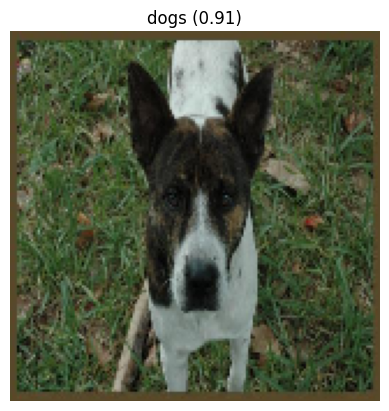

In [17]:
img, pred, classe, conf = predict_image(path_class2, model, class_names)

plt.imshow(img[0].numpy().astype("uint8"))
plt.title(f"{classe} ({conf:.2f})")
plt.axis('off')
plt.show()

# Ataques Adversariais

## Fast Gradient Signed Method (FGSM)

### Funções úteis para a realização do FGSM

In [18]:
# Implement FGSM adversarial attack
def create_adversarial_perturbation_FGSM(input_image, input_label, model):
    loss_object = tf.keras.losses.BinaryCrossentropy()

    with tf.GradientTape() as tape:
        tape.watch(input_image)
        prediction = model(input_image, training=False)
        loss = loss_object(input_label, prediction)

    gradient = tape.gradient(loss, input_image)
    return tf.sign(gradient)

# Construct adversarial sample by adding the original image and its adversarial perturbation
def construct_adversarial_samples(clean_sample, perturbation, epsilons):
    adversarial_samples = []

    for e in epsilons:
        adv = clean_sample + e * perturbation
        adv = tf.clip_by_value(adv, 0.0, 255.0)
        adversarial_samples.append(adv)

    return adversarial_samples

## Realizando o ataque

### Recuperando o label da imagem

In [19]:
# Get image input label
img, pred, class_name, confidence = predict_image(path_class1, model, class_names)

print("prediction:", pred)
print("class:", class_name)
print("confidence:", confidence)

prediction: 0.41664267
class: cats
confidence: 0.58335733


### Criando a perturbação adversarial

In [20]:
desired_class = 0  # escolha 0 ou 1

for images, labels in val_ds.unbatch():
    if labels.numpy() == desired_class:
        image1 = tf.expand_dims(images, 0)
        label_raw = labels
        break

label = tf.expand_dims(tf.cast(label_raw, tf.float32), axis=0)

In [21]:
# Get FGSM adversarial perturbation for the sample image
adversarial_perturbation = create_adversarial_perturbation_FGSM(image1, label, model)

### Exibindo a perturbação gerada

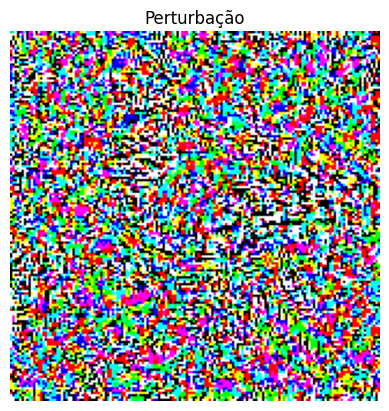

In [22]:
# Print the FGSM adversarial perturbation of the sample image
# print(adversarial_perturbation.shape)
pert = adversarial_perturbation[0]

pert = (pert - tf.reduce_min(pert)) / (tf.reduce_max(pert) - tf.reduce_min(pert))

plt.imshow(pert)
plt.title("Perturbação")
plt.axis('off')
plt.show()

### Criando o Exemplo Adversarial

In [23]:
# Define epsilon values
epsilons = [0, 2, 5, 15, 25]

epsilons_descriptions = [
    ('Input' if eps == 0 else f'Epsilon = {eps:.2f}')
    for eps in epsilons
]

print(epsilons_descriptions)

# Get adversarial samples
adversarial_samples = construct_adversarial_samples(image1, adversarial_perturbation, epsilons)

['Input', 'Epsilon = 2.00', 'Epsilon = 5.00', 'Epsilon = 15.00', 'Epsilon = 25.00']


### Classificando os exemplos adversariais

In [24]:
adv_batch = tf.concat(adversarial_samples, axis=0)
preds = model.predict(adv_batch, verbose=0)

image_probs_list = []
class_name_list = []
confidence_score_list = []

for i, pred in enumerate(preds):
    prob = float(pred[0])

    pred_class = int(prob >= 0.5)
    class_name = class_names[pred_class]

    confidence_score = prob if pred_class == 1 else 1 - prob

    image_probs_list.append(prob)
    class_name_list.append(class_name)
    confidence_score_list.append(confidence_score)

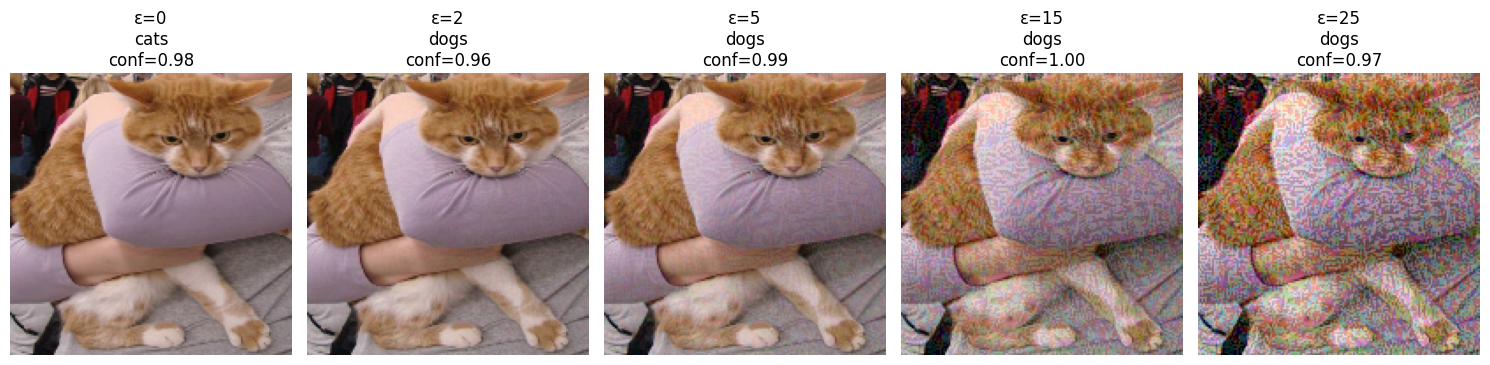

In [25]:
plt.figure(figsize=(15, 4))

n = len(epsilons)

for i in range(n):
    prob = float(preds[i][0])

    pred_class = int(prob >= 0.5)
    class_name = class_names[pred_class]

    confidence = prob if pred_class == 1 else 1 - prob

    img = adversarial_samples[i].numpy()
    img = np.squeeze(img)

    img = np.clip(img, 0, 255).astype("uint8")

    plt.subplot(1, n, i + 1)
    plt.imshow(img)
    plt.title(f"ε={epsilons[i]}\n{class_name}\nconf={confidence:.2f}")
    plt.axis("off")

plt.tight_layout()
plt.show()